<a href="https://colab.research.google.com/github/Riyendo/game/blob/main/Coding_VIT_archtitecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torchvision

In [2]:
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
import numpy as np
import torch.utils.data as dataloader
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [3]:
transformations = transforms.Compose([
    transforms.ToTensor()
])

In [4]:
trainset = torchvision.datasets.MNIST(root='./data', train=True,
                                        download=True, transform=transformations)
valset = torchvision.datasets.MNIST(root='./data', train=False,
                                        download=True, transform=transformations)

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 337kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.14MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.4MB/s]


In [5]:
train_data = torch.utils.data.DataLoader(trainset, batch_size=64,
                                          shuffle=True, num_workers=2)
val_data = torch.utils.data.DataLoader(valset, batch_size=64,
                                          shuffle=True, num_workers=2)

In [6]:
class PatchEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = nn.Conv2d(1, 16, kernel_size=7, stride=7)

    def forward(self, x):
        x =  self.embed(x)
        x = x.flatten(2)
        x =  x.transpose(1, 2)


        return x

In [7]:
class Transformations(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_norm1 = nn.LayerNorm(16)
        self.multihead_attention = nn.MultiheadAttention(16, 4, batch_first=True)
        self.layer_norm2 = nn.LayerNorm(16)
        self.feed_forward = nn.Sequential(
            nn.Linear(16,256),
            nn.ReLU(),
            nn.Linear(256,128),
            nn.ReLU(),
            nn.Linear(128,16)
        )
    def forward(self, x):
        residual1 = x
        x = self.layer_norm1(x)
        x,_ = self.multihead_attention(x, x, x)
        x = x + residual1
        residual2 = x
        x = self.layer_norm2(x)
        x = self.feed_forward(x)
        x += residual2
        return x

In [8]:
class MLP_head(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_norm = nn.LayerNorm(16)
        self.linear = nn.Linear(16, 10)
    def forward(self, x):
        x = self.layer_norm(x)
        x = self.linear(x)
        return x


In [9]:
class VisionTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_embedding = PatchEmbedding()
        self.class_token = nn.Parameter(torch.randn(1, 1, 16))
        self.pos_embedding = nn.Parameter(torch.randn(1, 17, 16))

        self.transformer_block = Transformations()
        self.mlp_head = MLP_head()

    def forward(self, x):
        x = self.patch_embedding(x)
        b = x.shape[0]
        class_token = self.class_token.expand(b, -1, -1)
        x = torch.cat([class_token, x], dim=1)
        x = x + self.pos_embedding
        x = self.transformer_block(x)
        x = x[:, 0]
        x = self.mlp_head(x)
        return x

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = VisionTransformer().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()

In [11]:
images, labels = next(iter(train_data))
print(images.shape)

torch.Size([64, 1, 28, 28])


In [12]:
patch_nn = nn.Conv2d(1, 16, kernel_size=7, stride=7)
print(patch_nn(images).shape)

torch.Size([64, 16, 4, 4])


In [14]:
# We can determine the total number of images from the dataset length
total_images = len(trainset)

for i in range(10):
    train_acc = 0.0
    correct_images = 0.0
    model.train()

    for images, labels in train_data:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        predictions = torch.argmax(outputs, dim=1)
        correct_predictions = (predictions == labels).sum().item()
        # Corrected: Accumulate the correct predictions across all batches
        correct_images += correct_predictions

    print(f"Epoch {i+1}: Train Accuracy = {correct_images / total_images * 100:.2f}%")

Epoch 1: Train Accuracy = 77.77%
Epoch 2: Train Accuracy = 89.30%
Epoch 3: Train Accuracy = 90.45%
Epoch 4: Train Accuracy = 91.63%
Epoch 5: Train Accuracy = 92.01%
Epoch 6: Train Accuracy = 92.52%
Epoch 7: Train Accuracy = 92.75%
Epoch 8: Train Accuracy = 93.16%
Epoch 9: Train Accuracy = 93.47%
Epoch 10: Train Accuracy = 93.85%


In [15]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_data:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

test_acc = 100.0 * correct / total
print(f"\n==> Val Accuracy: {test_acc:.2f}%")


==> Val Accuracy: 93.27%


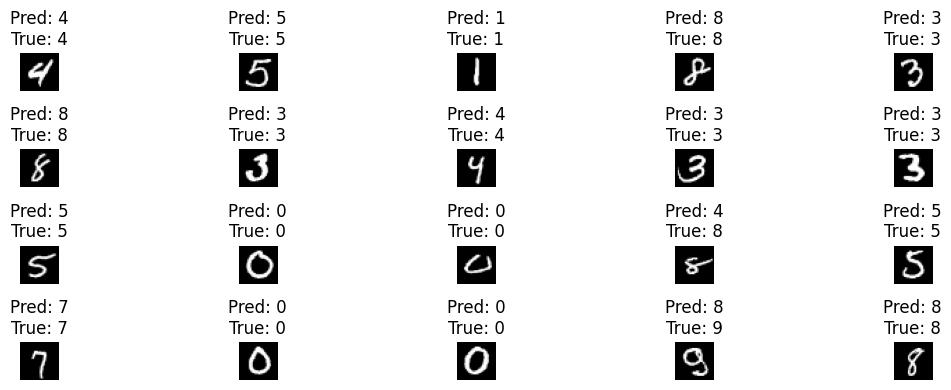

In [17]:
model.eval()
images, labels = next(iter(val_data))
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    outputs = model(images)
    preds = outputs.argmax(dim=1)

plt.figure(figsize=(12, 4))
for i in range(20):
    plt.subplot(4, 5, i+1)
    plt.imshow(images[i].squeeze().cpu(), cmap='gray')
    plt.title(f"Pred: {preds[i].item()}\nTrue: {labels[i].item()}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [2]:
git init()


SyntaxError: invalid syntax (4255473218.py, line 1)